# Lab 2 — What Did the Campaign Deliver?
Name: Adelina Khytrenko | Group: КМ-43

## Setup

In [16]:
import kagglehub
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
DATA = kagglehub.dataset_download("shkarupylomaxim/adtech-lab1-tv-panel/versions/3")
programs = pd.read_parquet(f"{DATA}/programs.parquet")
viewings = pd.read_parquet(f"{DATA}/viewings.parquet")
daily_weights = pd.read_parquet(f"{DATA}/daily_weights.parquet")
viewer_attributes = pd.read_parquet(f"{DATA}/viewer_attributes.parquet")
attributes = pd.read_parquet(f"{DATA}/attributes.parquet")
commercials = pd.read_parquet(f"{DATA}/commercials.parquet")
rate_card = pd.read_parquet(f"{DATA}/rate_card.parquet")

100%|██████████| 8.00M/8.00M [00:00<00:00, 148MB/s]

Extracting files...


In [17]:
# Lab 1 rules: persons are R and L only (households and guests are not persons)
viewings_p = viewings[viewings['resp_type'].isin(['R', 'L'])].copy()
dw_p = daily_weights[daily_weights['resp_type'].isin(['R', 'L'])].copy()

# check the codes I use: 300 = age in years, 201 / 202 = sex
print(attributes[attributes['attr_id'].isin([201, 202, 300])][['attr_id', 'attr_group', 'attr_name']])

age = (viewer_attributes[viewer_attributes['attr_id'] == 300]
       .drop_duplicates('respondent_id').set_index('respondent_id')['value'])
sex = (viewer_attributes[viewer_attributes['attr_id'].isin([201, 202])]
       .drop_duplicates('respondent_id').set_index('respondent_id')['attr_id']
       .map({201: 'M', 202: 'F'}))

dw_p['age'] = dw_p['respondent_id'].map(age)
dw_p['sex'] = dw_p['respondent_id'].map(sex)
dw_p['is_a1849'] = dw_p['age'].between(18, 49)

# one weight per person for the month = average weight over the in-tab days
persons = dw_p.groupby('respondent_id').agg(month_w=('weight', 'mean'), age=('age', 'first'), sex=('sex', 'first'))
persons['is_a1849'] = persons['age'].between(18, 49)

# universe of every broadcast day (sum of weights of everyone in-tab) and number of persons in-tab
day_univ_p2 = dw_p.groupby('broadcast_date')['weight'].sum()
day_univ_t = dw_p[dw_p['is_a1849']].groupby('broadcast_date')['weight'].sum()
day_n_tab = dw_p.groupby('broadcast_date').size()

BIG = ['CBS', 'NBC', 'ABC', 'FOX', 'FNC']
SMALL = ['FX', 'BRAVO', 'HGTV', 'FOOD', 'HIST']

def reach_pct(resp_ids, target=False):
    """weighted reach (%) of a set of respondent ids, for P2+ or for A18-49"""
    pool = persons[persons['is_a1849']] if target else persons
    return pool.loc[pool.index.isin(resp_ids), 'month_w'].sum() / pool['month_w'].sum() * 100

def wmedian(x, w):
    x, w = np.asarray(x), np.asarray(w)
    o = np.argsort(x)
    cw = np.cumsum(w[o])
    return x[o][np.searchsorted(cw, cw[-1] / 2)]

   attr_id attr_group     attr_name
4      201        Sex          Male
5      202        Sex        Female
6      300        Age  Age in years


## Task 1.1 — Size

In [18]:
ba_all = commercials[commercials['brand'] == 'BRAND_A']
print("Spots:", commercials['ad_airing_id'].nunique())
print("Pods:", commercials[['telecast_id', 'pod_id']].drop_duplicates().shape[0])  # a pod = pod_id inside its telecast
print("Brands:", commercials['brand'].nunique())
print("Categories:", commercials['category'].nunique())
print("BRAND_A spots:", ba_all['ad_airing_id'].nunique())
ba_all.groupby('network_code').size().rename('BRAND_A spots').to_frame()

Spots: 167720
Pods: 22359
Brands: 95
Categories: 14
BRAND_A spots: 300


,BRAND_A spots
network_code,
ABC,29
BRAVO,33
CBS,22
FNC,40
FOOD,33
FOX,13
FX,38
HGTV,39
HIST,37


## Task 1.2 — Ad load

In [19]:
c = commercials.copy()
c['hour'] = c['start_ts'].dt.floor('h')   # clock hour in which the spot started

# ad seconds in every clock hour of every network, then the average over the hours that had ads
hourly = c.groupby(['network_code', 'hour'])['length_sec'].sum().reset_index()
g = hourly.groupby('network_code')['length_sec']
ad_load = pd.DataFrame({'ad_min_per_hour': g.mean() / 60, 'hours_with_ads': g.count()})

# all hours of the month on the network (programs cover every minute of the month)
ad_load['hours_total'] = programs.groupby('network_code')['duration_min'].sum() / 60
ad_load['share_hours_no_ads'] = 1 - ad_load['hours_with_ads'] / ad_load['hours_total']

ad_load = ad_load.sort_values('ad_min_per_hour', ascending=False)
print("Heaviest ad load:", ad_load.index[0], round(ad_load['ad_min_per_hour'].iloc[0], 1))
ad_load.round({'ad_min_per_hour': 1, 'hours_total': 0, 'share_hours_no_ads': 3})

Heaviest ad load: FNC 15.6


,ad_min_per_hour,hours_with_ads,hours_total,share_hours_no_ads
network_code,,,,
FNC,15.6,743,744.0,0.001
BRAVO,13.4,623,744.0,0.163
HGTV,13.3,621,744.0,0.165
HIST,13.2,622,744.0,0.164
FOOD,13.1,620,744.0,0.167
FX,12.9,621,744.0,0.165
CBS,12.1,427,744.0,0.426
ABC,11.8,349,744.0,0.531
NBC,11.8,299,744.0,0.598


**Answer:** The heaviest ad load is on FNC: about 15.6 ad minutes per hour, and it has ads in 743 of the 744 hours of the month. The other cable networks have 12.9 to 13.4 minutes per hour and the broadcast networks 11.8 to 12.1. The broadcast networks have many hours without any national ads because those hours belong to the local stations (`Local / Syndicated Programming`). The breaks there are sold locally by the stations, so they are not in `commercials`. This is visible in the column `share_hours_no_ads`: it is 0.426 for CBS, 0.531 for ABC, 0.598 for NBC and 0.737 for FOX, but only 0.001 for FNC and about 0.16 for the other cable networks (these hours are probably paid programming, which also has no commercials).

## Task 1.3 — Price everything

In [20]:
# program name and broadcast day of every spot
spots = commercials.merge(programs[['telecast_id', 'program_name', 'broadcast_date']], on='telecast_id', how='left')

# split the rate card: program rows have a program name, time rows do not
is_prog = rate_card['program_name'].notna() & (rate_card['program_name'] != '')
rc_prog = rate_card[is_prog][['network_code', 'program_name', 'daypart', 'cost_30s_usd']]
rc_time = rate_card[~is_prog].copy()

# step 1: program rows win -> match on network and program name
n_spots = len(spots)
spots = spots.merge(rc_prog.rename(columns={'daypart': 'sell_daypart', 'cost_30s_usd': 'cost_30'}),
                    on=['network_code', 'program_name'], how='left')
assert len(spots) == n_spots
spots['price_type'] = np.where(spots['cost_30'].notna(), 'program', 'time')

# step 2: all other spots -> time rows. broadcast weekday and minute of the broadcast day (06:00 = 0)
shifted = spots['start_ts'] - pd.Timedelta(hours=6)
spots['bd_weekday'] = shifted.dt.dayofweek
spots['minute'] = shifted.dt.hour * 60 + shifted.dt.minute

def to_min(s):
    hm = s.str.split(':', expand=True).astype(int)
    return hm[0] * 60 + hm[1] - 360          # 25:37 -> 25*60 + 37 - 360

rc_time['start_min'] = to_min(rc_time['start_time'])
rc_time['end_min'] = to_min(rc_time['end_time'])
rc_time = rc_time.explode('weekdays').rename(columns={'weekdays': 'bd_weekday'})   # one row per weekday
rc_time['bd_weekday'] = rc_time['bd_weekday'].astype(int)

todo = spots['price_type'] == 'time'
rest = spots.loc[todo, ['ad_airing_id', 'network_code', 'bd_weekday', 'minute']].merge(
    rc_time[['network_code', 'bd_weekday', 'start_min', 'end_min', 'daypart', 'cost_30s_usd']],
    on=['network_code', 'bd_weekday'], how='left')
rest = rest[(rest['minute'] >= rest['start_min']) & (rest['minute'] < rest['end_min'])]
assert rest['ad_airing_id'].is_unique    # every spot falls in exactly one time row
rest = rest.set_index('ad_airing_id')

spots.loc[todo, 'sell_daypart'] = spots.loc[todo, 'ad_airing_id'].map(rest['daypart'])
spots.loc[todo, 'cost_30'] = spots.loc[todo, 'ad_airing_id'].map(rest['cost_30s_usd'])

# :15 costs half of the :30 price, :60 costs twice
spots['cost'] = spots['cost_30'] * spots['length_sec'] / 30

print("Spots without a price:", int(spots['cost'].isna().sum()))

tot = spots.groupby('network_code')['cost'].sum()
prog = spots[spots['price_type'] == 'program'].groupby('network_code')['cost'].sum()
value = pd.DataFrame({'value_usd_m': tot / 1e6, 'share_program_rows': (prog / tot).fillna(0)})
value.round({'value_usd_m': 2, 'share_program_rows': 3})

Spots without a price: 0


,value_usd_m,share_program_rows
network_code,,
ABC,708.79,0.432
BRAVO,25.31,0.000
CBS,818.78,0.230
FNC,315.85,0.000
FOOD,42.15,0.000
FOX,696.17,0.835
FX,42.51,0.000
HGTV,58.10,0.000
HIST,40.09,0.000


## Task 2.1 — Delivery

In [21]:
# BRAND_A spots
ba = spots[spots['brand'] == 'BRAND_A'].copy()

# who saw each spot: watching the same network at the spot start (session start <= spot start < session end)
spot_ids, resp_ids = [], []
for net, sp in ba.groupby('network_code'):
    vn = viewings_p[viewings_p['network_code'] == net]
    s, e, rid = vn['start_ts'].values, vn['end_ts'].values, vn['respondent_id'].values
    for ad_id, t in zip(sp['ad_airing_id'], sp['start_ts'].values):
        hit = (s <= t) & (e > t)
        spot_ids.append(np.full(hit.sum(), ad_id))
        resp_ids.append(rid[hit])
exposures = pd.DataFrame({'ad_airing_id': np.concatenate(spot_ids), 'respondent_id': np.concatenate(resp_ids)})
exposures = exposures.drop_duplicates()

# add the spot's network and broadcast day, and the person's weight and demographics for that day
exposures = exposures.merge(ba[['ad_airing_id', 'network_code', 'broadcast_date']], on='ad_airing_id')
n_before = len(exposures)
exposures = exposures.merge(dw_p[['respondent_id', 'broadcast_date', 'weight', 'age', 'sex', 'is_a1849']],
                            on=['respondent_id', 'broadcast_date'], how='inner')
print("Exposure rows:", len(exposures), "| dropped (person not in-tab that day):", n_before - len(exposures))

# one row per BRAND_A spot with impressions and ratings
spot_tab = ba.set_index('ad_airing_id')[['network_code', 'sell_daypart', 'broadcast_date', 'cost']].copy()
spot_tab['imp_p2'] = exposures.groupby('ad_airing_id')['weight'].sum()
spot_tab['imp_t'] = exposures[exposures['is_a1849']].groupby('ad_airing_id')['weight'].sum()
spot_tab[['imp_p2', 'imp_t']] = spot_tab[['imp_p2', 'imp_t']].fillna(0)
spot_tab['rating_p2'] = spot_tab['imp_p2'] / spot_tab['broadcast_date'].map(day_univ_p2) * 100
spot_tab['rating_t'] = spot_tab['imp_t'] / spot_tab['broadcast_date'].map(day_univ_t) * 100
print("BRAND_A spots in spot_tab:", len(spot_tab))

Exposure rows: 11289 | dropped (person not in-tab that day): 0
BRAND_A spots in spot_tab: 300


In [22]:
imp_p2, imp_t = spot_tab['imp_p2'].sum(), spot_tab['imp_t'].sum()
grp_p2, grp_t = spot_tab['rating_p2'].sum(), spot_tab['rating_t'].sum()
reach_p2 = reach_pct(exposures['respondent_id'].unique())
reach_t = reach_pct(exposures.loc[exposures['is_a1849'], 'respondent_id'].unique(), target=True)

print("P2+ impressions (M):", round(imp_p2 / 1e6, 1))
print("P2+ GRPs:", round(grp_p2, 1))
print("P2+ reach (%):", round(reach_p2, 1))
print("P2+ average frequency:", round(grp_p2 / reach_p2, 2))
print("A18-49 impressions (M):", round(imp_t / 1e6, 1))
print("A18-49 GRPs:", round(grp_t, 1))
print("A18-49 reach (%):", round(reach_t, 1))
print("A18-49 average frequency:", round(grp_t / reach_t, 2))

P2+ impressions (M): 418.8
P2+ GRPs: 132.0
P2+ reach (%): 43.5
P2+ average frequency: 3.03
A18-49 impressions (M): 81.1
A18-49 GRPs: 60.4
A18-49 reach (%): 30.5
A18-49 average frequency: 1.98


## Task 2.2 — Frequency distribution

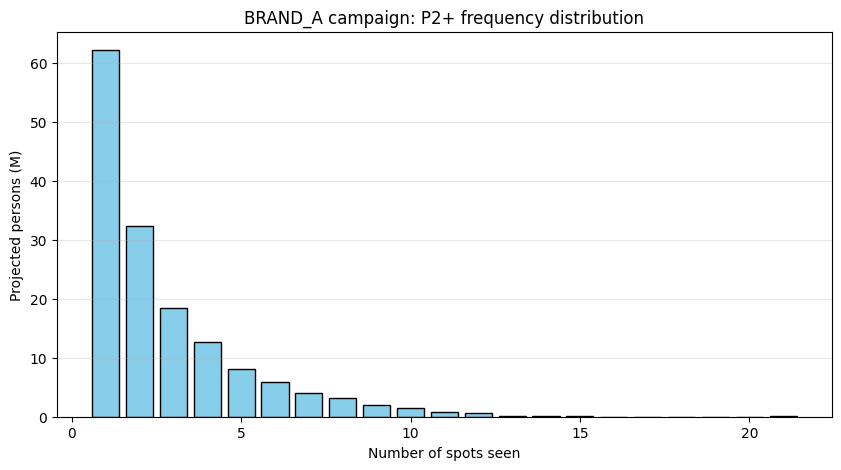

Share of impressions at 5+ exposures: 0.444
Persons reached (M): 152.3
Weighted mean frequency of reached persons: 2.75
Weighted median frequency of reached persons: 2
Share of reached persons with 1 spot only: 0.409


In [23]:
# frequency = number of BRAND_A spots a person saw; people are projected with their monthly weight
freq = exposures.groupby('respondent_id').size().rename('freq')
fd = persons.loc[freq.index, ['month_w']].join(freq)
dist = (fd.groupby('freq')['month_w'].sum() / 1e6).reindex(range(1, fd['freq'].max() + 1), fill_value=0)

plt.figure(figsize=(10, 5))
plt.bar(dist.index, dist.values, color='skyblue', edgecolor='black')
plt.title('BRAND_A campaign: P2+ frequency distribution')
plt.xlabel('Number of spots seen')
plt.ylabel('Projected persons (M)')
plt.grid(True, alpha=0.3, axis='y')
plt.show()

exposures['freq'] = exposures['respondent_id'].map(freq)
share5 = exposures.loc[exposures['freq'] >= 5, 'weight'].sum() / exposures['weight'].sum()
print("Share of impressions at 5+ exposures:", round(share5, 3))

# extra numbers for the answer
print("Persons reached (M):", round(fd['month_w'].sum() / 1e6, 1))
print("Weighted mean frequency of reached persons:", round(np.average(fd['freq'], weights=fd['month_w']), 2))
print("Weighted median frequency of reached persons:", wmedian(fd['freq'], fd['month_w']))
print("Share of reached persons with 1 spot only:", round(dist.iloc[0] / dist.sum(), 3))

**Answer:** The average frequency is 3.03 (the weighted mean among the reached persons is 2.75), but the median is only 2 and 0.409 of the reached persons saw just one spot. The people with 5 or more exposures are a small tail on the plot, but they got 0.444 of all impressions. So the distribution is strongly skewed to the right: most people saw 1 or 2 spots and a few heavy viewers saw more than 20. The average is pulled up by this tail, so it is not a fair summary and does not describe a typical person. In a report I would show the distribution (for example how many people were reached 1, 2 and 3+ times) together with the average.

## Task 2.3 — On target?

In [24]:
print("Share of impressions on A18-49:", round(imp_t / imp_p2, 3))

# extra: how big the target is in the population, and the target share network by network
print("A18-49 share of all persons:", round(persons.loc[persons['is_a1849'], 'month_w'].sum() / persons['month_w'].sum(), 3))
by_net = spot_tab.groupby('network_code').agg(spots=('cost', 'size'), imp_p2=('imp_p2', 'sum'), imp_t=('imp_t', 'sum'))
by_net['share_of_all_imp'] = by_net['imp_p2'] / by_net['imp_p2'].sum()
by_net['share_a1849'] = by_net['imp_t'] / by_net['imp_p2']
by_net[['imp_p2', 'imp_t']] = (by_net[['imp_p2', 'imp_t']] / 1e6).round(1)
by_net.sort_values('share_a1849').round({'share_of_all_imp': 3, 'share_a1849': 3})

Share of impressions on A18-49: 0.194
A18-49 share of all persons: 0.422


,spots,imp_p2,imp_t,share_of_all_imp,share_a1849
network_code,,,,,
FNC,40,57.8,2.7,0.138,0.047
CBS,22,89.0,13.7,0.212,0.154
ABC,29,94.2,17.0,0.225,0.180
NBC,16,41.4,7.8,0.099,0.189
HIST,37,12.3,2.5,0.029,0.202
FOX,13,76.3,18.4,0.182,0.242
HGTV,39,24.7,7.6,0.059,0.306
FOOD,33,9.5,3.0,0.023,0.316
BRAVO,33,5.1,2.8,0.012,0.554


**Answer:** Only 0.194 of the impressions landed on A18-49, while this group is 0.422 of all persons. So the campaign under-delivered against its target: its share on the target is less than half of the target's share in the population. The table shows which networks explain it. All big networks have a low A18-49 share (FNC 0.047, CBS 0.154, ABC 0.180, NBC 0.189, FOX 0.242), and together they have about 0.86 of all impressions. FNC is the worst case: it has 0.138 of all impressions, but only 2.7M of its 57.8M impressions are A18-49. Only FX (0.651) and BRAVO (0.554) are above 0.422, but they have just 0.020 and 0.012 of the impressions.

## Task 3.1 — Cost

In [25]:
total_cost = spot_tab['cost'].sum()
print("Campaign cost (USD):", int(round(total_cost)))
print("P2+ CPM (USD):", round(total_cost / imp_p2 * 1000, 2))
print("P2+ CPP (USD):", int(round(total_cost / grp_p2)))
print("A18-49 CPM (USD):", round(total_cost / imp_t * 1000, 2))
print("A18-49 CPP (USD):", int(round(total_cost / grp_t)))

Campaign cost (USD): 7420270
P2+ CPM (USD): 17.72
P2+ CPP (USD): 56221
A18-49 CPM (USD): 91.53
A18-49 CPP (USD): 122836


## Task 3.2 — By network

In [26]:
net_tab = spot_tab.groupby('network_code').agg(spots=('cost', 'size'), cost=('cost', 'sum'),
                                               imp_p2=('imp_p2', 'sum'), imp_t=('imp_t', 'sum'))
net_tab['share_of_cost'] = net_tab['cost'] / net_tab['cost'].sum()
net_tab['p2_cpm'] = (net_tab['cost'] / net_tab['imp_p2'] * 1000).replace(np.inf, np.nan)
net_tab['a1849_cpm'] = (net_tab['cost'] / net_tab['imp_t'] * 1000).replace(np.inf, np.nan)
net_tab['imp_p2'] = net_tab['imp_p2'] / 1e6
net_tab['imp_t'] = net_tab['imp_t'] / 1e6
net_tab = net_tab.rename(columns={'imp_p2': 'imp_p2_M', 'imp_t': 'imp_a1849_M'})
net_tab.sort_values('a1849_cpm').round({'cost': 0, 'share_of_cost': 3, 'imp_p2_M': 1, 'imp_a1849_M': 1,
                                        'p2_cpm': 2, 'a1849_cpm': 2})

,spots,cost,imp_p2_M,imp_a1849_M,share_of_cost,p2_cpm,a1849_cpm
network_code,,,,,,,
FX,38,92200.0,8.5,5.6,0.012,10.82,16.61
BRAVO,33,49610.0,5.1,2.8,0.007,9.76,17.61
HGTV,39,230000.0,24.7,7.6,0.031,9.33,30.45
HIST,37,79640.0,12.3,2.5,0.011,6.46,32.05
FOOD,33,96620.0,9.5,3.0,0.013,10.19,32.29
ABC,29,1625700.0,94.2,17.0,0.219,17.26,95.69
NBC,16,796800.0,41.4,7.8,0.107,19.23,101.72
CBS,22,1488700.0,89.0,13.7,0.201,16.73,108.72
FOX,13,2434700.0,76.3,18.4,0.328,31.93,132.03


**Answer:** Most of the money went to the big networks: FOX 0.328 of the cost, ABC 0.219, CBS 0.201, NBC 0.107 and FNC 0.071, so about 0.93 together. The small networks got only about 0.07. For A18-49 the cheapest networks are FX (\$16.61 CPM) and BRAVO (\$17.61), then HGTV, HIST and FOOD (about \$30 to \$32). The most expensive are FNC (\$193.70) and FOX (\$132.03). FNC is cheap for P2+ (\$9.11), but its audience is old, so it is the most expensive one for the target. FOX is the most expensive network per spot (\$2.43M for 13 spots, about \$187,000 per spot, which fits with 0.835 of its rate-card value coming from program rows, i.e. sports), but it delivered fewer P2+ impressions (76.3M) than ABC (94.2M) and CBS (89.0M), which cost less. So its P2+ CPM is the highest (\$31.93).

## Task 3.3 — Guarantee

In [27]:
GUARANTEE = 150
owed = max(0.0, GUARANTEE - grp_p2)
print("Guarantee met:", bool(grp_p2 >= GUARANTEE))
print("Make-good GRPs owed:", round(owed, 1))
print("Value of make-goods (USD):", int(round(owed * total_cost / grp_p2)))   # at the campaign's P2+ CPP

Guarantee met: False
Make-good GRPs owed: 18.0
Value of make-goods (USD): 1012869


**Answer:** No, the guarantee was not met: the campaign delivered 132.0 P2+ GRPs against the 150 guaranteed. The networks owe 18.0 GRPs of make-goods, which is worth about \$1,012,869 at the campaign's P2+ CPP of $56,221 per point.

## Task 4 — Do networks add up?

In [28]:
ids_big = exposures.loc[exposures['network_code'].isin(BIG), 'respondent_id'].unique()
ids_small = exposures.loc[exposures['network_code'].isin(SMALL), 'respondent_id'].unique()
ids_all = exposures['respondent_id'].unique()
ids_both = np.intersect1d(ids_big, ids_small)

reach_big, reach_small, reach_all = reach_pct(ids_big), reach_pct(ids_small), reach_pct(ids_all)
overlap = reach_pct(ids_both)
overlap_indep = reach_big * reach_small / 100

cost_big = spot_tab.loc[spot_tab['network_code'].isin(BIG), 'cost'].sum()
cost_small = spot_tab.loc[spot_tab['network_code'].isin(SMALL), 'cost'].sum()
added = reach_all - reach_big

print("Reach, big networks (%):", round(reach_big, 1))
print("Reach, small networks (%):", round(reach_small, 1))
print("Reach, whole campaign (%):", round(reach_all, 1))
print("Overlap (%):", round(overlap, 1))
print("Overlap if independent (%):", round(overlap_indep, 1))
print("Reach added by small networks (points):", round(added, 1))
print("Cost per added reach point, small (USD):", int(round(cost_small / added)))
print("Cost per reach point, big (USD):", int(round(cost_big / reach_big)))

# extra checks for the answer
print("Check, big + small - whole (%):", round(reach_big + reach_small - reach_all, 1))
print("Small-network reached persons who were also reached by big (%):", round(overlap / reach_small * 100, 1))

Reach, big networks (%): 39.8
Reach, small networks (%): 12.4
Reach, whole campaign (%): 43.5
Overlap (%): 8.7
Overlap if independent (%): 4.9
Reach added by small networks (points): 3.7
Cost per added reach point, small (USD): 148706
Cost per reach point, big (USD): 172456
Check, big + small - whole (%): 8.7
Small-network reached persons who were also reached by big (%): 70.2


**Answer:** Reach counts every person once. People who saw BRAND_A spots on both a big and a small network are inside both group reaches but only once in the whole campaign, so the whole is smaller than the sum: 39.8% + 12.4% − 8.7% = 43.5% (not 52.2%). If the two audiences were independent, the overlap would be 39.8 × 12.4 / 100 = 4.9%, but the real overlap is 8.7%, almost twice as much. Among the people reached by the small networks, 70.2% were also reached by the big ones, compared with 39.8% in the whole population. So the small-network viewers are more likely than average to be reached by the big networks. A possible reason is that heavy TV viewers watch many networks, so the same people are in both audiences. The small networks added 3.7 points of reach and each added point cost \$148,706, while a reach point on the big networks cost $172,456. So the small-network money was reasonably well spent: the extra reach was about 14% cheaper per point, but it is a small addition (the small networks got only about 7% of the budget) and it is based on few panelists (see Task 5).

## Task 5 — How sure are we?

In [29]:
# panelists (unweighted R and L persons) who saw each spot; spots that nobody saw get 0
spot_tab['n_panel'] = exposures.groupby('ad_airing_id')['respondent_id'].nunique()
spot_tab['n_panel'] = spot_tab['n_panel'].fillna(0).astype(int)

# standard error of the P2+ rating (simple random sample formula), in rating points
spot_tab['n_tab'] = spot_tab['broadcast_date'].map(day_n_tab)
p = spot_tab['rating_p2'] / 100
spot_tab['se'] = np.sqrt(p * (1 - p) / spot_tab['n_tab']) * 100
spot_tab['rel_se'] = spot_tab['se'] / spot_tab['rating_p2']
spot_tab.loc[spot_tab['rating_p2'] == 0, 'rel_se'] = np.nan   # undefined when the rating is 0
spot_tab['group'] = np.where(spot_tab['network_code'].isin(BIG), 'big', 'small')

# table by network
t5 = spot_tab.groupby('network_code').agg(group=('group', 'first'), spots=('n_panel', 'size'),
                                          median_panelists=('n_panel', 'median'),
                                          spots_no_panelist=('n_panel', lambda s: int((s == 0).sum())),
                                          median_rel_se=('rel_se', 'median'))
display(t5.sort_values(['group', 'median_panelists']).round({'median_rel_se': 3}))

print("Spots seen by no panelist:", int((spot_tab['n_panel'] == 0).sum()))
print("Rating of those spots:", spot_tab.loc[spot_tab['n_panel'] == 0, 'rating_p2'].max() if (spot_tab['n_panel'] == 0).any() else "no such spots")
print("Median relative SE, big networks:", round(spot_tab.loc[spot_tab['group'] == 'big', 'rel_se'].median(), 3))
print("Median relative SE, small networks:", round(spot_tab.loc[spot_tab['group'] == 'small', 'rel_se'].median(), 3))

# W18-34 zero-cells: spots that no woman aged 18-34 in the panel saw
w1834 = exposures[(exposures['sex'] == 'F') & exposures['age'].between(18, 34)]
n_w1834 = w1834.groupby('ad_airing_id')['respondent_id'].nunique().reindex(spot_tab.index, fill_value=0)
print("W18-34 zero-cell spots:", int((n_w1834 == 0).sum()))

# extra: how many W18-34 are in the panel on an average day
print("W18-34 panelists in-tab, average day:", round(dw_p[(dw_p['sex'] == 'F') & dw_p['age'].between(18, 34)].groupby('broadcast_date').size().mean()))

,group,spots,median_panelists,spots_no_panelist,median_rel_se
network_code,,,,,
FNC,big,40,31.0,0,0.164
ABC,big,29,57.0,0,0.123
NBC,big,16,68.5,0,0.115
CBS,big,22,69.0,0,0.113
FOX,big,13,145.0,0,0.080
BRAVO,small,33,3.0,3,0.540
FOOD,small,33,5.0,2,0.423
HIST,small,37,5.0,1,0.460
FX,small,38,5.5,4,0.423


Spots seen by no panelist: 10
Rating of those spots: 0.0
Median relative SE, big networks: 0.122
Median relative SE, small networks: 0.417
W18-34 zero-cell spots: 171
W18-34 panelists in-tab, average day: 952


**Answer:** A zero rating does not mean that nobody watched the spot, it means that no panelist watched it. The panel is only a sample, so a small audience can fall between the panelists and the spot gets a rating of 0.0 although its real audience is above 0. The SE formula even gives 0 for these spots, which is misleading, so I left them out of the relative SE. 10 spots were seen by no panelist and all of them are on small networks (FX 4, BRAVO 3, FOOD 2, HIST 1). The median number of panelists per spot is between 31 and 145 on the big networks, but only 3 to 11 on the small networks. The median relative SE is 0.122 for the big and 0.417 for the small networks, so the ratings of the small networks are very uncertain, and since a weighted panel behaves like a smaller one, the real errors are even bigger. For W18-34, 171 of the 300 spots are zero-cells, although about 952 W18-34 panelists are in-tab on an average day. I would tell the client that a W18-34 rating by spot is not possible with this panel: more than half of the spots were not seen by a single woman aged 18-34, so the cells are too small. They should look at a bigger cell (A18-49, or the whole campaign) or add up many spots, and we should show the error margin together with the numbers.

## Bonus

In [30]:
# cost per A18-49 thousand impressions for every network + selling daypart that BRAND_A bought
grp = spot_tab.groupby(['network_code', 'sell_daypart']).agg(spots=('cost', 'size'), cost=('cost', 'sum'), imp_t=('imp_t', 'sum'))
grp['cpm_t'] = (grp['cost'] / grp['imp_t'] * 1000).replace(np.inf, np.nan)
grp['cpm_t_sort'] = grp['cpm_t'].fillna(np.inf)       # groups with no target impressions are the worst

# the 20 spots that sit in the most expensive network + daypart cells
tmp = spot_tab.reset_index().merge(grp[['cpm_t_sort']].reset_index(), on=['network_code', 'sell_daypart'], how='left')
moved = tmp.sort_values('cpm_t_sort', ascending=False).head(20)

# cheapest cell with at least 5 spots (so that it is not just 1-2 lucky spots)
ok = grp[(grp['spots'] >= 5) & grp['cpm_t'].notna()]
best_key = ok['cpm_t'].idxmin()
best_cpm = ok['cpm_t'].min()

moved_cost, moved_imp = moved['cost'].sum(), moved['imp_t'].sum()
new_imp_t = imp_t - moved_imp + moved_cost / best_cpm * 1000

print("Moved spots come from:", moved.groupby(['network_code', 'sell_daypart']).size().to_dict())
print("Moved budget (USD):", int(round(moved_cost)), "| A18-49 impressions of these spots (M):", round(moved_imp / 1e6, 2))
print("Target cell:", best_key, "with A18-49 CPM", round(best_cpm, 2))
print("A18-49 impressions after the move (M):", round(new_imp_t / 1e6, 2), "vs before", round(imp_t / 1e6, 2))
print("A18-49 CPM before:", round(total_cost / imp_t * 1000, 2), "| after:", round(total_cost / new_imp_t * 1000, 2))

Moved spots come from: {('CBS', 'Daytime'): 4, ('FNC', 'Daytime News'): 9, ('FNC', 'Early Evening'): 3, ('FNC', 'Prime Opinion'): 2, ('NBC', 'Prime'): 2}
Moved budget (USD): 707800 | A18-49 impressions of these spots (M): 1.99
Target cell: ('FX', 'Daytime Movies') with A18-49 CPM 11.9
A18-49 impressions after the move (M): 138.58 vs before 81.07
A18-49 CPM before: 91.53 | after: 53.54


**Answer:** I would move the budget of the 20 spots in the most expensive A18-49 cells (FNC Daytime News 9 spots, CBS Daytime 4, FNC Early Evening 3, FNC Prime Opinion 2, NBC Prime 2) to FX Daytime Movies, where the A18-49 CPM is \$11.90. These 20 spots cost \$707,800 and gave only 1.99M A18-49 impressions. The same money in the new cell would give about 59.5M, so the A18-49 impressions of the campaign would go from 81.1M to 138.6M and the A18-49 CPM would fall from \$91.53 to $53.54. This is only an estimate: it assumes that the CPM stays the same when we buy much more, it is based on FX spots with few panelists (Task 5), and more spots on FX would repeat the same people, so reach would grow less than impressions.